# CLL mtscATAC-seq (3/4): the genes of each clone and Fig. 4e

Step 3 of the CLL analysis (`03a_cll.ipynb` → `03b_cll_gene_activity.R` → this notebook → `03d_cll_coverage.R`).

- Input: the gene activity from `03b_cll_gene_activity.R` (`analysis/results/cll/r_output/gene_activity/`) and the fit `output/v2/cll/202610/11/080706` (see `03a_cll.ipynb`).
- Output: `analysis/results/cll/` (one PDF per panel; the ranked genes of every clone as CSV, also read by `03d_cll_coverage.R`).

In [1]:
%cd ../src

.../cloneVI/src


.../site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [2]:
import os

import numpy as np
import pandas as pd
import scanpy as sc
import scipy.io
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import seaborn as sns
from matplotlib.lines import Line2D

In [3]:
GA = '../analysis/results/cll/r_output/gene_activity'
RUN = '../output/v2/cll/202610/11/080706'
OUT = '../analysis/results/cll'

### Figure style

The same in every notebook of the paper. Panels are drawn at their print size, so that text and points match in the assembled figures. Every UMAP panel has the same size and frame. Colours of the UMAP panels as in the original analysis notebooks: clonal probability and VAF in cubehelix maps (from 0 to the largest value of the panel), two clones in the end colours of viridis, expression in viridis. Heatmaps keep the colour maps of the original notebooks (for $\phi$ the seaborn default).

In [4]:
plt.rcParams.update({'font.size': 6.5, 'axes.titlesize': 7, 'axes.labelsize': 6.5, 'xtick.labelsize': 6,
                     'ytick.labelsize': 6, 'legend.fontsize': 6, 'axes.linewidth': 0.5, 'xtick.major.width': 0.5,
                     'ytick.major.width': 0.5, 'xtick.major.size': 2, 'ytick.major.size': 2, 'savefig.dpi': 600})
PI_CMAP = sns.cubehelix_palette(start=.5, rot=-.5, as_cmap=True)
VAF_CMAP = sns.cubehelix_palette(as_cmap=True)
EXPR_CMAP = 'viridis'
MAP_SIZE = (2.0, 1.6)    # inches, every UMAP panel: map 1.36 in wide, colour bar or legend on the right


def new_map():
    fig = plt.figure(figsize=MAP_SIZE)
    ax = fig.add_axes([0.01, 0.02, 0.68, 0.84])
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)
    return fig, ax


def map_values(xy, v, cmap, title, label, s, vmin=0, vmax=None):
    # continuous values, high values drawn on top
    fig, ax = new_map()
    vmax = float(np.max(v)) if vmax is None else vmax
    o = np.argsort(v)
    ax.scatter(xy[o, 0], xy[o, 1], c=v[o], cmap=cmap, vmin=vmin, vmax=vmax, s=s, linewidths=0, rasterized=RASTER)
    ax.set_aspect('equal', adjustable='datalim')
    cb = fig.colorbar(plt.cm.ScalarMappable(plt.Normalize(vmin, vmax), cmap), cax=fig.add_axes([0.72, 0.12, 0.03, 0.62]))
    cb.outline.set_visible(False)
    cb.set_label(label)
    ax.set_title(title)
    return fig, ax


def map_groups(xy, groups, colors, title, s, labels=None, on_data=False, legend=True, seed=0):
    # categories, cells drawn in a fixed random order so that no group hides another
    fig, ax = new_map()
    o = np.random.default_rng(seed).permutation(len(groups))
    ax.scatter(xy[o, 0], xy[o, 1], c=[colors[g] for g in groups[o]], s=s, linewidths=0, rasterized=RASTER)
    ax.set_aspect('equal', adjustable='datalim')
    labels = labels or {g: str(g) for g in colors}
    if on_data:
        for g in colors:
            x, y = np.median(xy[groups == g], axis=0)
            ax.text(x, y, labels[g], ha='center', va='center', fontweight='bold',
                    path_effects=[pe.withStroke(linewidth=1.5, foreground='white')])
    elif legend:
        ax.legend(handles=legend_handles(colors, labels), loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False,
                  handletextpad=0.1)
    ax.set_title(title)
    return fig, ax


def legend_handles(colors, labels):
    return [Line2D([], [], marker='o', ls='', markersize=3, color=colors[g], label=labels[g]) for g in colors]


def legend_panel(colors, labels, ncol=1):
    # a legend as its own panel, for maps with many groups
    fig, ax = plt.subplots(figsize=(0.5, 0.5))
    ax.axis('off')
    ax.legend(handles=legend_handles(colors, labels), loc='center', ncol=ncol, frameon=False, handletextpad=0.1,
              columnspacing=1.0)
    return fig


def save(fig, name):
    # maps keep their fixed size; other panels are cropped to their content
    fixed = fig.get_size_inches().tolist() == list(MAP_SIZE)
    fig.savefig(f'{OUT}/{name}.pdf', bbox_inches=None if fixed else 'tight')

In [5]:
S = 1.0                                 # point size of the UMAP panels (5,610 cells), as in 03a
RASTER = True

## 1. Gene activity

The fragments in the gene body and 2 kb upstream of each protein-coding gene, for the genes with fragments in more than 50 cells (`03b_cll_gene_activity.R`).

In [6]:
ga = sc.AnnData(scipy.io.mmread(f'{GA}/matrix.mtx').T.tocsr().astype(float),
                obs=pd.read_csv(f'{GA}/barcodes.tsv', sep='\t', index_col=0, keep_default_na=False),
                var=pd.read_csv(f'{GA}/genes.tsv', sep='\t', index_col=0, keep_default_na=False))
ga.var_names_make_unique()
adata_mg = sc.read_h5ad(f'{RUN}/cloneVI_result.h5ad')
assert (ga.obs_names == adata_mg.obs['barcode'].to_numpy()).all()
ga

.../site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


AnnData object with n_obs × n_vars = 5610 × 17783

Normalization (Methods): counts normalized to 10,000 per cell and log-transformed, the 2,000 most variable genes kept, and each gene divided by its mean over cells.

In [7]:
ga.X = ga.X.toarray()
sc.pp.normalize_total(ga, target_sum=1e4)
sc.pp.log1p(ga)
sc.pp.highly_variable_genes(ga, n_top_genes=2000)
ga = ga[:, ga.var['highly_variable']].copy()
ga.X = ga.X / ga.X.mean(axis=0)
ga

.../site-packages/scanpy/preprocessing/_highly_variable_genes.py:215: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disp_grouped = df.groupby('mean_bin')['dispersions']


AnnData object with n_obs × n_vars = 5610 × 2000
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'

## 2. The genes of each clone

The $\pi$-weighted mean gene activity of gene $g$ in clone $k$, $s_{gk} = \sum_c x_{gc}\pi_{ck} / \sum_c \pi_{ck}$ (Methods, as for the MAESTER data). The ten genes with the highest $s_{gk}$ in each clone:

In [8]:
pi = np.asarray(adata_mg.obsm['pi_deleted'], dtype=float)
s_gk = pd.DataFrame((ga.X.T @ pi) / pi.sum(0), index=ga.var_names)
top10 = pd.concat({f'Clone {k}': s_gk[k].sort_values(ascending=False).head(10).reset_index().set_axis(['gene', 's_gk'], axis=1)
                   for k in range(pi.shape[1])}, axis=1)
top10.round(2)

Clone 0        Clone 1           Clone 2              Clone 3        \
        gene  s_gk     gene  s_gk        gene  s_gk           gene  s_gk   
0     NAP1L3  1.14   ZNF257  4.04      CLEC4A  1.56           ALPP  3.11   
1       PAX9  1.14   NAP1L2  3.19   C20orf202  1.50        SULT1C4  1.91   
2      MYADM  1.13     ALPP  2.92       NR5A2  1.50  RP11-487E13.1  1.89   
3    LGALS12  1.13     MLNR  2.51  AL353354.2  1.48          PLIN4  1.76   
4       TCN1  1.13     KRT7  2.46      CYP4Z1  1.48          ADH1B  1.73   
5      TSHZ3  1.12    PTPN3  1.92     SCGB3A2  1.46          OLIG3  1.66   
6  C20orf202  1.11     JAG2  1.91       KCNA6  1.41        SLC39A2  1.65   
7        RGR  1.11  ZSCAN23  1.89        LIPG  1.41        CNTNAP3  1.62   
8  HIST1H2AE  1.11    FOXD1  1.88         RGR  1.41         ZNF257  1.61   
9  HIST1H2BG  1.11     LCA5  1.76       FAAH2  1.40         SLC7A3  1.59   

     Clone 4           Clone 5           Clone 6          Clone 7        \
        gene  s_gk        gene  s_gk        gene  s_gk       gene  s_gk   
0       PAX9  2.30      ZNF257  7.10       RAB32  3.14   HIST1H4E  2.22   
1  HIST1H2AE  2.17      NAP1L2  6.98       MYADM  2.08      TGFBI  2.22   
2  HIST1H2BG  2.15      ZNF730  5.47    HIST1H3E  2.07       GAS7  2.20   
3      OLIG3  2.13         VIP  5.41  AL162407.1  1.92     SPDYE4  2.13   
4   HIST1H4E  2.05     ARHGEF5  4.99     TNFAIP6  1.87      MYADM  2.11   
5       GAS1  1.98     RNASE13  4.74    HIST1H4D  1.85       PAX9  2.03   
6  HIST1H2BF  1.96      GPR171  4.42   HIST1H2BH  1.74   HIST1H3D  2.01   
7   HIST1H3D  1.94  AC004817.1  4.38    HIST1H4E  1.72   HIST1H4D  1.98   
8  HIST1H2AD  1.92      SLC7A9  4.05   HIST1H2AE  1.70  HIST1H2BF  1.97   
9   HIST1H3E  1.92       MS4A8  3.92       ADH1B  1.70  HIST1H2AE  1.94   

      Clone 8        
         gene  s_gk  
0     SLC10A5  4.87  
1     SPANXN4  4.77  
2       CTXN2  2.89  
3       BTNL3  2.64  
4     SLC39A2  2.55  
5       GALR1  2.47  
6  AC120194.1  2.47  
7       DACT2  2.42  
8   LINC00923  2.41  
9       PARVA  2.33

For the accessibility plots (`03d_cll_coverage.R`), the genes of each clone with $s_{gk} \geq 1.5$ (at least 1.5 times the mean over cells), up to 30, by rank.

In [9]:
ranked = {f'Clone_{k}': list(s_gk[k][s_gk[k] >= 1.5].sort_values(ascending=False).head(30).index) for k in range(pi.shape[1])}
clone_top_genes = pd.DataFrame({k: v + [''] * (30 - len(v)) for k, v in ranked.items()})
clone_top_genes.to_csv(f'{OUT}/clone_top_genes.csv', index=False)
pd.Series({k: len(v) for k, v in ranked.items()}, name='genes with s_gk >= 1.5')

Clone_0     0
Clone_1    20
Clone_2     2
Clone_3    15
Clone_4    17
Clone_5    30
Clone_6    18
Clone_7    28
Clone_8    30
Name: genes with s_gk >= 1.5, dtype: int64

PAX9 ranks first for Clone 4, and most of the following genes belong to the HIST1H cluster of replication-dependent histone genes (HIST1H2AE ranks second):

In [10]:
phi = np.asarray(adata_mg.varm['phi_deleted'], dtype=float)
K1260 = int(phi[[str(v) for v in adata_mg.var_names].index('1260')].argmax())   # the clone of 1260 (Clone 4)
print('clone of 1260:', K1260)
rank4 = list(s_gk[K1260].sort_values(ascending=False).index)
pd.DataFrame({'rank': [rank4.index(g) + 1 for g in rank4[:12]], 'gene': rank4[:12],
              's_gk': s_gk.loc[rank4[:12], K1260].round(2).to_numpy(), 'HIST1H': [g.startswith('HIST1H') for g in rank4[:12]]})

clone of 1260: 4


,rank,gene,s_gk,HIST1H
0,1,PAX9,2.30,False
1,2,HIST1H2AE,2.17,True
2,3,HIST1H2BG,2.15,True
3,4,OLIG3,2.13,False
4,5,HIST1H4E,2.05,True
5,6,GAS1,1.98,False
6,7,HIST1H2BF,1.96,True
7,8,HIST1H3D,1.94,True
8,9,HIST1H2AD,1.92,True
9,10,HIST1H3E,1.92,True


## 3. Fig. 4e: gene activity of the top gene of each clone

The normalized gene activity of section 1 on the CloneVI UMAP, for the first-ranked gene of every clone (Fig. 4e shows PAX9, Clone 4); colour scale up to the 99th percentile of the cells with activity.

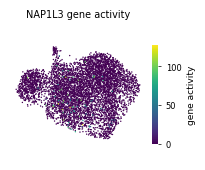

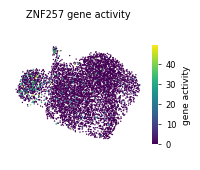

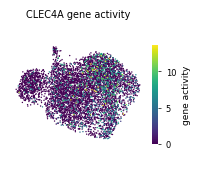

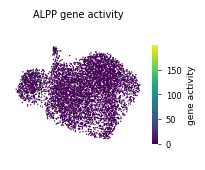

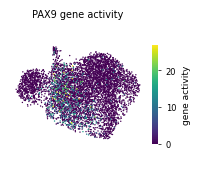

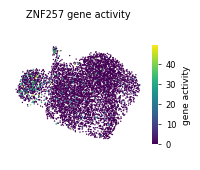

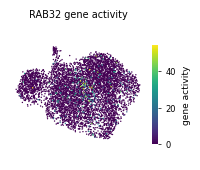

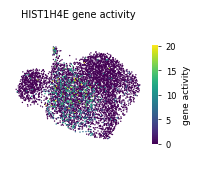

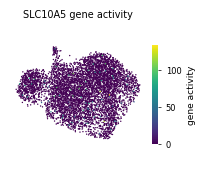

In [11]:
xy = adata_mg.obsm['X_cloneVI_umap']
top_values = {}
for k in range(pi.shape[1]):
    gene = s_gk[k].idxmax()
    v = np.asarray(ga[:, gene].X).ravel()
    top_values[gene] = v
    fig, ax = map_values(xy, v, EXPR_CMAP, f'{gene} gene activity', 'gene activity', S, vmax=np.quantile(v[v > 0], 0.99))
    save(fig, f'ga_clone{k}_{gene}')
# the values drawn, for the figure notebook (03e)
pd.DataFrame(top_values, index=adata_mg.obs['barcode'].to_numpy()).to_csv(f'{OUT}/ga_top_gene_of_each_clone.csv')

## 4. The numbers in the paper

`where` names the part of the paper: the Results section, a figure legend or alt text, a supplementary table or the Methods subsection.

In [12]:
hist_ranks = [rank4.index(g) + 1 for g in rank4[:12] if g.startswith('HIST1H')]
M = 'Methods (Downstream analysis of CLL mtscATAC-seq data)'
rows = [('genes kept after normalization', M, '2,000', f'{ga.n_vars:,}'),
        ('first-ranked gene of Clone 4', f'{M}; Results (CLL)', 'PAX9', rank4[0]),
        ('several HIST1H genes ranked high for Clone 4', 'Results (CLL); Supp. Fig. S4 legend', 'yes',
         'yes' if len(hist_ranks) >= 3 else 'no')]
numbers = pd.DataFrame(rows, columns=['item', 'where', 'paper', 'computed'])
numbers['match'] = numbers['paper'] == numbers['computed']
numbers.to_csv(f'{OUT}/numbers_03c.csv', index=False)
numbers, hist_ranks

(                                           item  \
 0                genes kept after normalization   
 1                  first-ranked gene of Clone 4   
 2  several HIST1H genes ranked high for Clone 4   
 
                                                where  paper computed  match  
 0  Methods (Downstream analysis of CLL mtscATAC-s...  2,000    2,000   True  
 1  Methods (Downstream analysis of CLL mtscATAC-s...   PAX9     PAX9   True  
 2                Results (CLL); Supp. Fig. S4 legend    yes      yes   True  ,
 [2, 3, 5, 7, 8, 9, 10, 11])